## Pregunta 2

In [10]:
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft2, ifft2, fftshift, ifftshift

try:
    import imageio.v3 as iio
except ImportError:
    iio = None

try:
    import cv2
except ImportError:
    cv2 = None

try:
    from skimage.restoration import denoise_bilateral
except ImportError:
    denoise_bilateral = None

OUTPUT_DIR = Path("plots_p2")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 120
EPS = 1e-6
print(f"Entorno listo | OpenCV: {cv2 is not None} | imageio: {iio is not None} | scikit-image: {denoise_bilateral is not None}")

Entorno listo | OpenCV: True | imageio: True | scikit-image: True


## 0. Carga de imágenes HDR, conversiones de color y métricas cuantitativas

### Convenciones explícitas de rango, normalización y conversiones:
- **Luminancia física (Rec. 709):** $Y = 0.2126 R + 0.7152 G + 0.0722 B$, operando sobre valores RGB lineales no negativos ($\max(C, 0)$).
- **Normalización de salida:** Tras la compresión HDR en dominio logarítmico, la luminancia comprimida $Y'$ se reescala de forma robusta usando los percentiles $(0.5\%, 99.5\%)$ y *clipping* estricto a $[0, 1]$ para evitar que píxeles especulares extremos aplasten el contraste global.
- **Imagen de referencia "Original" para visualizacion y metricas de tono/saturacion:** Dado que las imagenes HDR lineales no son directamente desplegables sin *clipping*, se construye una referencia lineal normalizada por percentil $99\%$ y se codifica con la funcion sRGB estandar por tramos. La misma codificacion se aplica a las reconstrucciones lineales antes de visualizarlas y medir su color.


In [11]:
def load_hdr_rgb(path):
    """Carga imagen HDR/TIFF en formato float64 RGB no negativo."""
    if not os.path.exists(path):
        raise FileNotFoundError(f"No se encontró: {path}")
    if iio is not None:
        img = iio.imread(path).astype(np.float64)
    elif cv2 is not None:
        img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
        if img is None:
            raise ValueError(f"No se pudo leer: {path}")
        img = img.astype(np.float64)
        if img.ndim == 3:
            img = img[..., ::-1]
    else:
        raise RuntimeError("Se requiere imageio o opencv-python.")
    if img.ndim == 3 and img.shape[2] > 3:
        img = img[..., :3]
    return np.maximum(img, 0.0)


def compute_luminance(rgb):
    """Calcula luminancia Rec. 709."""
    return 0.2126 * rgb[..., 0] + 0.7152 * rgb[..., 1] + 0.0722 * rgb[..., 2]


def robust_normalize_01(arr, p_low=0.5, p_high=99.5):
    """Normaliza un arreglo 2D o 3D a [0, 1] mediante percentiles robustos."""
    lo = np.percentile(arr, p_low)
    hi = np.percentile(arr, p_high)
    if hi - lo < EPS:
        hi = arr.max()
        lo = arr.min()
    if hi - lo < EPS:
        return np.zeros_like(arr, dtype=np.float64)
    return np.clip((arr - lo) / (hi - lo), 0.0, 1.0)


def linear_to_srgb(rgb_linear):
    """Codifica RGB lineal normalizado a sRGB para visualizacion y metricas."""
    rgb_linear = np.clip(rgb_linear, 0.0, 1.0)
    return np.where(
        rgb_linear <= 0.0031308,
        12.92 * rgb_linear,
        1.055 * np.power(rgb_linear, 1.0 / 2.4) - 0.055,
    )


def make_display_reference(rgb_hdr, p_white=99.0):
    """Normaliza RGB lineal por luminancia y lo codifica a sRGB para referencia."""
    Y = compute_luminance(rgb_hdr)
    white = np.percentile(Y, p_white)
    if white < EPS:
        white = np.max(Y) + EPS
    rgb_lin = np.clip(rgb_hdr / white, 0.0, 1.0)
    return linear_to_srgb(rgb_lin)


# ==============================================================================
# CONVERSIONES DE ESPACIO DE COLOR (IMPLEMENTACIÓN VECTORIZADA EXPLÍCITA)
# ==============================================================================
def rgb_to_hsv(rgb):
    """Convierte RGB en [0, 1] a HSV con H en [0, 1), S en [0, 1], V en [0, 1]."""
    rgb = np.clip(rgb, 0.0, 1.0)
    r, g, b = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    maxc = np.maximum(np.maximum(r, g), b)
    minc = np.minimum(np.minimum(r, g), b)
    v = maxc
    delta = maxc - minc

    s = np.where(maxc > EPS, delta / (maxc + EPS), 0.0)
    h = np.zeros_like(maxc)

    mask = delta > EPS
    rc = np.where(mask, (maxc - r) / (delta + EPS), 0.0)
    gc = np.where(mask, (maxc - g) / (delta + EPS), 0.0)
    bc = np.where(mask, (maxc - b) / (delta + EPS), 0.0)

    h = np.where(mask & (r == maxc), bc - gc, h)
    h = np.where(mask & (g == maxc), 2.0 + rc - bc, h)
    h = np.where(mask & (b == maxc), 4.0 + gc - rc, h)
    h = (h / 6.0) % 1.0
    return np.stack([h, s, v], axis=-1)


def hsv_to_rgb(hsv):
    """Convierte HSV (H en [0, 1), S en [0, 1], V en [0, 1]) a RGB en [0, 1]."""
    h = hsv[..., 0] % 1.0
    s = np.clip(hsv[..., 1], 0.0, 1.0)
    v = np.clip(hsv[..., 2], 0.0, 1.0)

    i = np.floor(h * 6.0).astype(np.int32)
    f = (h * 6.0) - i
    p = v * (1.0 - s)
    q = v * (1.0 - f * s)
    t = v * (1.0 - (1.0 - f) * s)
    i_mod = i % 6

    r = np.choose(i_mod, [v, q, p, p, t, v])
    g = np.choose(i_mod, [t, v, v, q, p, p])
    b = np.choose(i_mod, [p, p, t, v, v, q])
    return np.clip(np.stack([r, g, b], axis=-1), 0.0, 1.0)


def rgb_to_cielab(rgb):
    """Convierte sRGB [0, 1] a CIELab (D65) para medir croma C* y ángulo de tono."""
    rgb = np.clip(rgb, 0.0, 1.0)
    # Linealización sRGB
    lin = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    r, g, b = lin[..., 0], lin[..., 1], lin[..., 2]

    # Matriz sRGB -> XYZ (D65)
    X = 0.4124564 * r + 0.3575761 * g + 0.1804375 * b
    Y = 0.2126729 * r + 0.7151522 * g + 0.0721750 * b
    Z = 0.0193339 * r + 0.1191920 * g + 0.9503041 * b

    # Blanco de referencia D65
    Xn, Yn, Zn = 0.95047, 1.00000, 1.08883
    delta = 6.0 / 29.0

    def f_lab(t):
        return np.where(t > delta ** 3, np.cbrt(t), t / (3.0 * delta ** 2) + 4.0 / 29.0)

    fx, fy, fz = f_lab(X / Xn), f_lab(Y / Yn), f_lab(Z / Zn)
    L = 116.0 * fy - 16.0
    a = 500.0 * (fx - fy)
    b_lab = 200.0 * (fy - fz)
    return np.stack([L, a, b_lab], axis=-1)


def compute_color_metrics(rgb_ref, rgb_rec, raw_unclipped=None):
    """
    Cuantifica:
      - Saturación HSV media (S_mean) y Croma CIELab medio (C*_mean)
      - Cambio angular medio de tono (Delta_H_deg) en regiones cromáticas (S_ref > 0.1)
      - Porcentaje de píxeles con clipping (> 1.0 antes de recortar)
    """
    hsv_ref = rgb_to_hsv(rgb_ref)
    hsv_rec = rgb_to_hsv(rgb_rec)

    lab_rec = rgb_to_cielab(rgb_rec)
    chroma_rec = np.hypot(lab_rec[..., 1], lab_rec[..., 2])

    # Diferencia angular circular de tono en grados [0, 180]
    dh = np.abs(hsv_rec[..., 0] - hsv_ref[..., 0])
    dh = np.minimum(dh, 1.0 - dh) * 360.0

    # Evaluar cambio de tono donde existe color apreciable en la referencia
    chroma_mask = (hsv_ref[..., 1] > 0.10) & (hsv_ref[..., 2] > 0.05)
    mean_dh_deg = float(np.mean(dh[chroma_mask])) if np.any(chroma_mask) else 0.0

    if raw_unclipped is not None:
        clip_pct = float(100.0 * np.mean(np.any(raw_unclipped > 1.0, axis=-1)))
    else:
        clip_pct = 0.0

    return {
        "S_mean": float(np.mean(hsv_rec[..., 1])),
        "C_star_mean": float(np.mean(chroma_rec)),
        "Delta_H_deg": mean_dh_deg,
        "Clip_pct": clip_pct,
    }


# Cargar las dos imágenes seleccionadas: memorial.tif y belgium.tif
images_hdr = {
    "memorial": load_hdr_rgb(os.path.join("archivos_t4", "memorial.tif")),
    "belgium": load_hdr_rgb(os.path.join("archivos_t4", "belgium.tif")),
}

for name, img in images_hdr.items():
    Y_tmp = compute_luminance(img)
    dyn_range = np.percentile(Y_tmp, 99.9) / (np.percentile(Y_tmp[Y_tmp > 0], 0.1) + EPS)
    print(f"Imagen '{name}': shape={img.shape} | Rango Y=[{Y_tmp.min():.3e}, {Y_tmp.max():.3e}] | DR aprox={dyn_range:.1f}:1")

Imagen 'memorial': shape=(768, 512, 3) | Rango Y=[6.507e-04, 2.230e+02] | DR aprox=35206.1:1
Imagen 'belgium': shape=(769, 1025, 3) | Rango Y=[8.360e-07, 6.079e-01] | DR aprox=14953.9:1


## 1. Implementación de Métodos de Compresión HDR

### 1.1 Filtrado Homomórfico
Modela la imagen como producto de iluminancia (baja frecuencia) y reflectancia (alta frecuencia), $I(x, y) = L(x, y) \cdot R(x, y)$. En dominio logarítmico $\ln(I + \epsilon)$ se aplica un filtro pasa-altos enfatizado en frecuencia:
$$H(u, v) = (\gamma_H - \gamma_L)\left[1 - \exp\left(-c \frac{D^2(u, v)}{D_0^2}\right)\right] + \gamma_L$$
- **Parámetros fijos utilizados:** $\gamma_L = 0.25$ (atenúa variaciones lentas de iluminación), $\gamma_H = 1.65$ (realza reflectancia/detalle local), $c = 1.0$, y frecuencia de corte $D_0 = 0.08 \cdot \min(H, W)$ en píxeles espectrales. Se aplica *padding* reflejado para evitar artefactos de periodicidad de la FFT.

### 1.2 Método de Durand (Separación Base/Detalle mediante Filtro Bilateral)
En dominio logarítmico $L_{\log} = \log_{10}(Y + \epsilon)$:
1. Se descompone en una **capa base** $B = \text{Bilateral}(L_{\log}; \sigma_s, \sigma_r)$ (preserva bordes fuertes de iluminación, suaviza texturas) y una **capa de detalle** $D = L_{\log} - B$.
2. Se comprime el contraste de la capa base mediante un factor de escala $k = \frac{\log_{10}(\text{target\_contrast})}{\max(B) - \min(B)}$:
   $$L'_{\log} = k \cdot (B - \max(B)) + D$$
3. Se retorna al dominio lineal $Y' = 10^{L'_{\log}}$ y se normaliza robustamente a $[0, 1]$.
- **Parámetros fijos utilizados:** $\sigma_s = 0.02 \cdot \max(H, W)$ (radio espacial proporcional al tamaño de imagen), $\sigma_r = 0.4$ (en décadas logarítmicas), y contraste objetivo `target_contrast = 5.0`.

In [12]:
def homomorphic_filter_2d(channel, gamma_l=0.25, gamma_h=1.65, c=1.0, d0_ratio=0.08):
    """Aplica filtrado homomórfico en dominio logarítmico con padding reflejado."""
    H, W = channel.shape
    # Normalizar escala interna para estabilidad del logaritmo
    scale = np.percentile(channel, 99.9) + EPS
    ch_norm = np.maximum(channel / scale, 0.0)
    log_img = np.log(ch_norm + 1e-4)

    # Padding reflejado para eliminar wrap-around de la FFT
    pad_h, pad_w = H // 2, W // 2
    padded = np.pad(log_img, ((pad_h, pad_h), (pad_w, pad_w)), mode="reflect")
    Hp, Wp = padded.shape

    u = np.arange(Hp) - Hp // 2
    v = np.arange(Wp) - Wp // 2
    V, U = np.meshgrid(v, u)
    D2 = U ** 2 + V ** 2
    D0 = d0_ratio * min(Hp, Wp)

    H_filt = (gamma_h - gamma_l) * (1.0 - np.exp(-c * (D2 / (D0 ** 2 + EPS)))) + gamma_l

    F = fftshift(fft2(padded))
    filtered_padded = np.real(ifft2(ifftshift(F * H_filt)))
    filtered_log = filtered_padded[pad_h:pad_h + H, pad_w:pad_w + W]

    out = np.exp(filtered_log)
    return robust_normalize_01(out, p_low=0.5, p_high=99.5)


def fast_bilateral_2d(img_2d, sigma_spatial, sigma_range):
    """Filtro bilateral 2D usando OpenCV (float32) o scikit-image como respaldo."""
    if cv2 is not None:
        # d=-1 calcula diámetro automáticamente desde sigmaSpace
        return cv2.bilateralFilter(
            img_2d.astype(np.float32),
            d=-1,
            sigmaColor=float(sigma_range),
            sigmaSpace=float(sigma_spatial)
        ).astype(np.float64)
    elif denoise_bilateral is not None:
        return denoise_bilateral(
            img_2d,
            sigma_color=sigma_range,
            sigma_spatial=sigma_spatial,
            channel_axis=None
        ).astype(np.float64)
    else:
        raise RuntimeError("Se requiere opencv-python o scikit-image para el filtro bilateral.")


def durand_tonemap_2d(channel, sigma_s_ratio=0.02, sigma_r=0.4, target_contrast=5.0):
    """Aplica compresión HDR de Durand (separación base/detalle bilateral en log10)."""
    H, W = channel.shape
    scale = np.percentile(channel, 99.9) + EPS
    ch_norm = np.maximum(channel / scale, 0.0)
    log_lum = np.log10(ch_norm + 1e-5)

    sigma_s = max(2.0, sigma_s_ratio * max(H, W))
    base = fast_bilateral_2d(log_lum, sigma_spatial=sigma_s, sigma_range=sigma_r)
    detail = log_lum - base

    b_max = np.percentile(base, 99.8)
    b_min = np.percentile(base, 0.2)
    base_range = max(b_max - b_min, EPS)

    compression_factor = np.log10(target_contrast) / base_range
    log_out = compression_factor * (base - b_max) + detail

    out = np.power(10.0, log_out)
    return robust_normalize_01(out, p_low=0.5, p_high=99.5)


def apply_hdr_per_channel_rgb(rgb_hdr, method_fn, **kwargs):
    """Aplica el operador HDR de forma independiente a R, G y B (comparación ingenua)."""
    channels = [method_fn(rgb_hdr[..., c], **kwargs) for c in range(3)]
    return np.stack(channels, axis=-1)


# Parámetros fijos para toda la Pregunta 2
HOMO_PARAMS = dict(gamma_l=0.25, gamma_h=1.65, c=1.0, d0_ratio=0.08)
DURAND_PARAMS = dict(sigma_s_ratio=0.02, sigma_r=0.4, target_contrast=5.0)
print("Parámetros fijos Homomórfico:", HOMO_PARAMS)
print("Parámetros fijos Durand:", DURAND_PARAMS)

Parámetros fijos Homomórfico: {'gamma_l': 0.25, 'gamma_h': 1.65, 'c': 1.0, 'd0_ratio': 0.08}
Parámetros fijos Durand: {'sigma_s_ratio': 0.02, 'sigma_r': 0.4, 'target_contrast': 5.0}


## 2. Estrategias de Reconstrucción de Color

1. **Estrategia 1 — Relación de cromaticidad con parámetro $\beta$:**
   $$C'_{\text{raw}} = Y' \cdot \left(\frac{C}{Y + \epsilon}\right)^\beta, \qquad C \in \{R, G, B\}$$
   - Se utiliza $\epsilon = 10^{-6}$ (relativo a la luminancia escalada) para evitar divisiones por cero en píxeles completamente negros.
   - Antes de desplegar, valores mayores a $1.0$ se recortan mediante `np.clip(C'_raw, 0.0, 1.0)` y se contabiliza el porcentaje de píxeles que sufrieron *clipping*.

2. **Estrategia 2 — Ajuste explícito de saturación $S$ en espacio HSV:**
   - Se parte de la reconstrucción que preserva la cromaticidad física lineal ($\beta = 1.0$, es decir, $C_0 = \text{clip}(Y' \cdot \frac{C}{Y + \epsilon}, 0, 1)$), se transforma a HSV $(H, S, V)$ y se escala explícitamente la saturación:
     $$S' = \text{clip}(k_S \cdot S, 0.0, 1.0)$$
   - Probamos $k_S \in \{0.6, 1.0, 1.4\}$, donde $k_S = 1.0$ es exactamente la **identidad** sobre la imagen base, $k_S = 0.6$ desatura y $k_S = 1.4$ intensifica el color sin alterar el ángulo de tono $H$ ni el valor $V$.

In [13]:
def reconstruct_color_beta(rgb_hdr, Y_orig, Y_comp, beta=1.0, eps=1e-6):
    """
    Estrategia 1: C' = Y' * (C / (Y + eps))^beta.
    Retorna (rgb_clipped, rgb_unclipped) para medir clipping explícitamente.
    """
    # Escalar rgb_hdr y Y_orig por el mismo factor para consistencia numérica de eps
    scale = np.percentile(Y_orig, 99.0) + eps
    rgb_s = np.maximum(rgb_hdr / scale, 0.0)
    Y_s = np.maximum(Y_orig / scale, 0.0)

    ratio = rgb_s / (Y_s[..., None] + eps)
    rgb_raw = Y_comp[..., None] * np.power(ratio, beta)
    rgb_clipped = np.clip(rgb_raw, 0.0, 1.0)
    rgb_display = linear_to_srgb(rgb_clipped)
    return rgb_display, rgb_raw


def reconstruct_color_hsv_saturation(rgb_hdr, Y_orig, Y_comp, sat_gain=1.0, eps=1e-6):
    """
    Estrategia 2: Parte de reconstrucción base (beta=1), convierte a HSV y escala S -> sat_gain * S.
    sat_gain = 1.0 corresponde a la identidad.
    """
    rgb_base, _ = reconstruct_color_beta(rgb_hdr, Y_orig, Y_comp, beta=1.0, eps=eps)
    hsv = rgb_to_hsv(rgb_base)
    s_raw = hsv[..., 1] * sat_gain
    hsv_mod = hsv.copy()
    hsv_mod[..., 1] = np.clip(s_raw, 0.0, 1.0)
    rgb_out = hsv_to_rgb(hsv_mod)
    # Reportamos también saturación fuera de [0, 1] como clipping de croma
    raw_proxy = np.where(s_raw[..., None] > 1.0, 1.05, rgb_out)
    return rgb_out, raw_proxy

## 3. Ejecución de Experimentos y Cuantificación del Comportamiento del Color

Ejecutamos ambos métodos HDR (`Homomórfico` y `Durand`) sobre ambas imágenes (`memorial` y `belgium`), evaluando:
- Canal RGB independiente (línea base)
- Estrategia 1 con $\beta \in \{0.6, 1.0, 1.4\}$
- Estrategia 2 (HSV $S$) con $k_S \in \{0.6, 1.0, 1.4\}$

In [14]:
betas = [0.6, 1.0, 1.4]
sat_gains = [0.6, 1.0, 1.4]

results = {}

for img_name, rgb_hdr in images_hdr.items():
    Y_orig = compute_luminance(rgb_hdr)
    rgb_ref = make_display_reference(rgb_hdr, p_white=99.0)
    ref_metrics = compute_color_metrics(rgb_ref, rgb_ref)

    results[img_name] = {
        "Y_orig": Y_orig,
        "rgb_ref": rgb_ref,
        "ref_metrics": ref_metrics,
        "methods": {}
    }

    print(f"==========================================================================")
    print(f"IMAGEN: {img_name.upper()} | Ref sRGB -> S_mean={ref_metrics['S_mean']:.3f}, C*_mean={ref_metrics['C_star_mean']:.2f}")
    print(f"==========================================================================")

    method_specs = [
        ("Homomórfico", homomorphic_filter_2d, HOMO_PARAMS),
        ("Durand", durand_tonemap_2d, DURAND_PARAMS),
    ]

    for m_name, m_fn, m_params in method_specs:
        Y_comp = m_fn(Y_orig, **m_params)
        rgb_indep = apply_hdr_per_channel_rgb(rgb_hdr, m_fn, **m_params)
        m_indep = compute_color_metrics(rgb_ref, rgb_indep)

        beta_res = {}
        for b in betas:
            rec_b, raw_b = reconstruct_color_beta(rgb_hdr, Y_orig, Y_comp, beta=b, eps=EPS)
            beta_res[b] = (rec_b, compute_color_metrics(rgb_ref, rec_b, raw_b))

        hsv_res = {}
        for ks in sat_gains:
            rec_k, raw_k = reconstruct_color_hsv_saturation(rgb_hdr, Y_orig, Y_comp, sat_gain=ks, eps=EPS)
            hsv_res[ks] = (rec_k, compute_color_metrics(rgb_ref, rec_k, raw_k))

        results[img_name]["methods"][m_name] = {
            "Y_comp": Y_comp,
            "rgb_indep": (rgb_indep, m_indep),
            "beta": beta_res,
            "hsv": hsv_res,
        }

        print(f"\n--- Método HDR: {m_name} ---")
        print(f"  {'Variante':<24} | {'S_mean':>7} | {'C*_mean':>8} | {'ΔH (°)':>7} | {'Clip (%)':>8}")
        print(f"  {'-'*64}")
        print(f"  {'RGB Independiente':<24} | {m_indep['S_mean']:7.3f} | {m_indep['C_star_mean']:8.2f} | {m_indep['Delta_H_deg']:7.2f} | {'N/A':>8}")
        for b in betas:
            mt = beta_res[b][1]
            print(f"  {f'Estrat. 1 (β = {b:.1f})':<24} | {mt['S_mean']:7.3f} | {mt['C_star_mean']:8.2f} | {mt['Delta_H_deg']:7.2f} | {mt['Clip_pct']:7.2f}%")
        for ks in sat_gains:
            mt = hsv_res[ks][1]
            tag = " (id)" if ks == 1.0 else ""
            print(f"  {f'Estrat. 2 (k_S = {ks:.1f}{tag})':<24} | {mt['S_mean']:7.3f} | {mt['C_star_mean']:8.2f} | {mt['Delta_H_deg']:7.2f} | {mt['Clip_pct']:7.2f}%")

IMAGEN: MEMORIAL | Ref sRGB -> S_mean=0.843, C*_mean=5.66

--- Método HDR: Homomórfico ---
  Variante                 |  S_mean |  C*_mean |  ΔH (°) | Clip (%)
  ----------------------------------------------------------------
  RGB Independiente        |   0.490 |     2.28 |    9.76 |      N/A
  Estrat. 1 (β = 0.6)      |   0.533 |    14.33 |    6.29 |    0.63%
  Estrat. 1 (β = 1.0)      |   0.725 |    22.28 |    3.76 |    0.73%
  Estrat. 1 (β = 1.4)      |   0.840 |    29.35 |    2.56 |    0.88%
  Estrat. 2 (k_S = 0.6)    |   0.435 |    12.97 |    3.76 |    0.00%
  Estrat. 2 (k_S = 1.0 (id)) |   0.725 |    22.28 |    3.76 |    0.00%
  Estrat. 2 (k_S = 1.4)    |   0.941 |    28.28 |    3.76 |   60.65%

--- Método HDR: Durand ---
  Variante                 |  S_mean |  C*_mean |  ΔH (°) | Clip (%)
  ----------------------------------------------------------------
  RGB Independiente        |   0.268 |     7.18 |   49.83 |      N/A
  Estrat. 1 (β = 0.6)      |   0.471 |    25.67 |    6.

### Lectura de las metricas

La luminancia y la relacion de cromaticidad se calculan sobre RGB lineal; antes de medir HSV/CIELAB o mostrar las reconstrucciones, se aplica a la referencia y a las salidas lineales la misma codificacion sRGB. Asi, el cambio de tono no compara una referencia codificada con una salida lineal.

En ambas imagenes, procesar R, G y B de forma independiente produce giros medios de tono mayores que la reconstruccion con $\beta=1$: en Durand, $49,83^\circ$ frente a $3,81^\circ$ para Memorial y $111,20^\circ$ frente a $0,15^\circ$ para Belgium. La saturacion explicita con $k_S=1$ coincide con la variante $\beta=1$, como corresponde a la identidad. En cambio, $k_S=1,4$ lleva la saturacion al limite para 60,65 % de pixeles en Memorial/Homomrfico y 29,12 % en Memorial/Durand; el porcentaje es menor en Belgium (1,75 % y 0,83 %). Este indicador corresponde al clipping de $S$ en HSV, no al clipping de canales RGB. Ademas, $C^*$ medio en Memorial/Durand pasa de 5,66 en la referencia a 40,20 con $\beta=1$ y a 52,94 con $\beta=1,4$, por lo que conviene leer el aumento de croma junto con el clipping y las figuras.

## 4. Visualización Comparativa: Luminancia Comprimida, RGB Independiente y Estrategias de Color

Generamos para cada imagen (`memorial` y `belgium`) una grilla completa donde se compara lado a lado:
- Fila 0: Referencia original sRGB, Luminancia comprimida $Y'$, y RGB independiente (mostrando el corrimiento de tono/desaturación).
- Fila 1: Estrategia 1 con $\beta \in \{0.6, 1.0, 1.4\}$.
- Fila 2: Estrategia 2 (HSV) con $k_S \in \{0.6, 1.0, 1.4\}$.

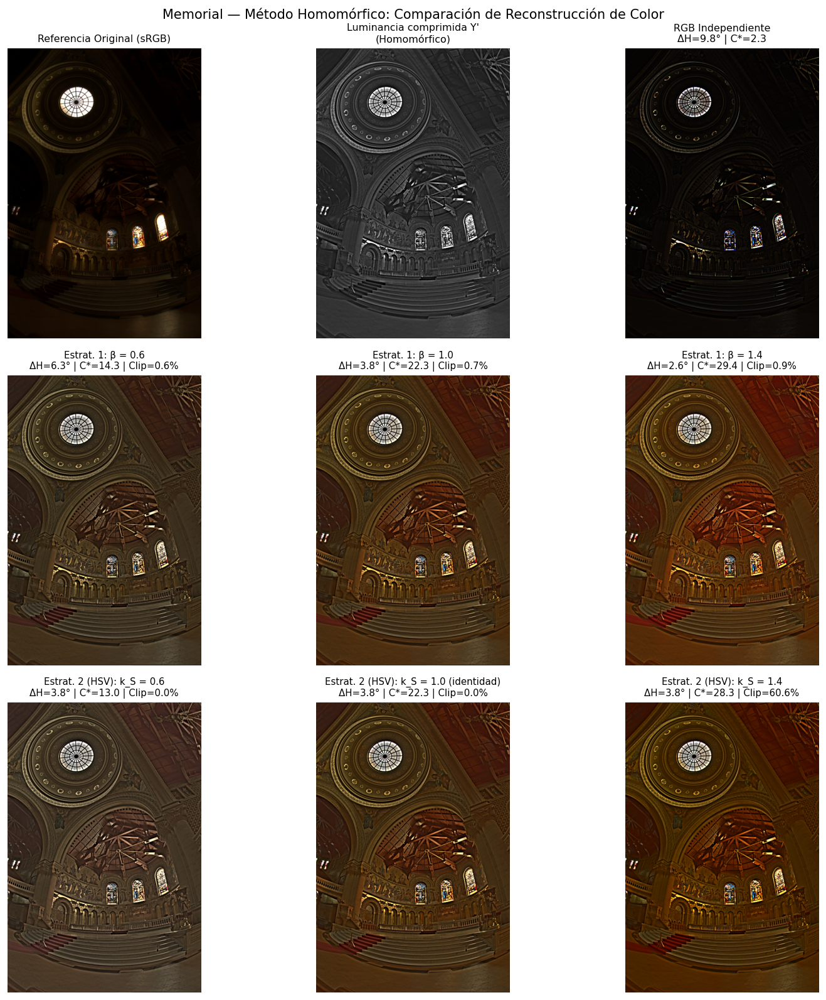

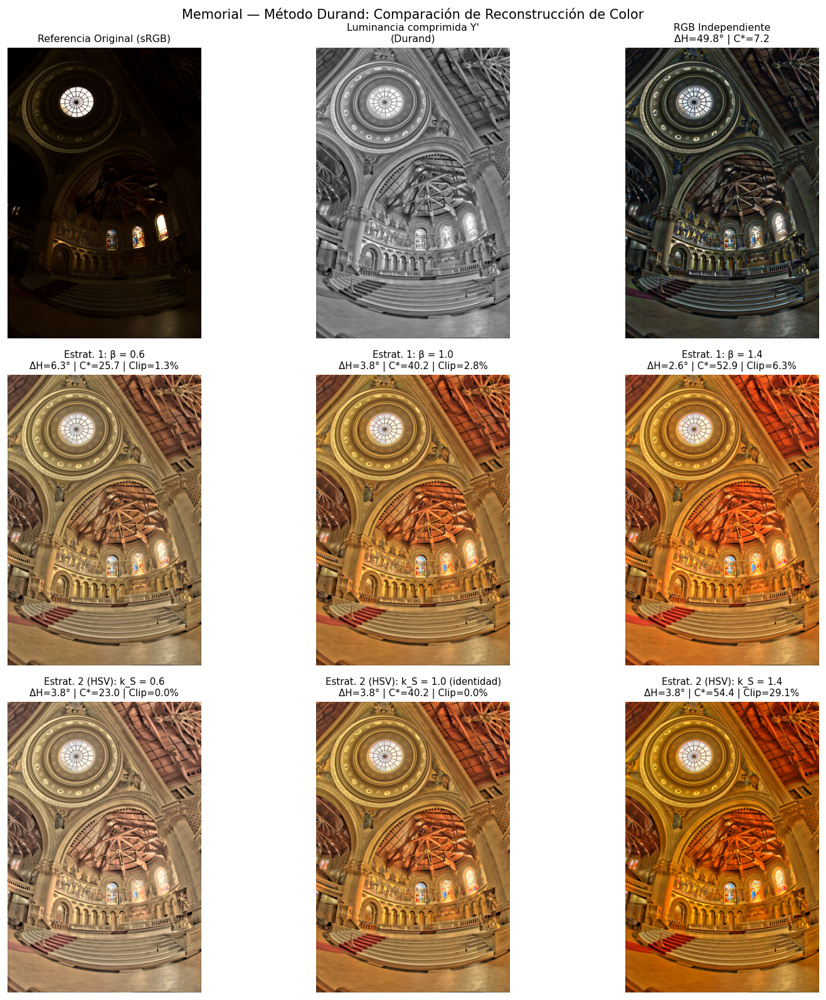

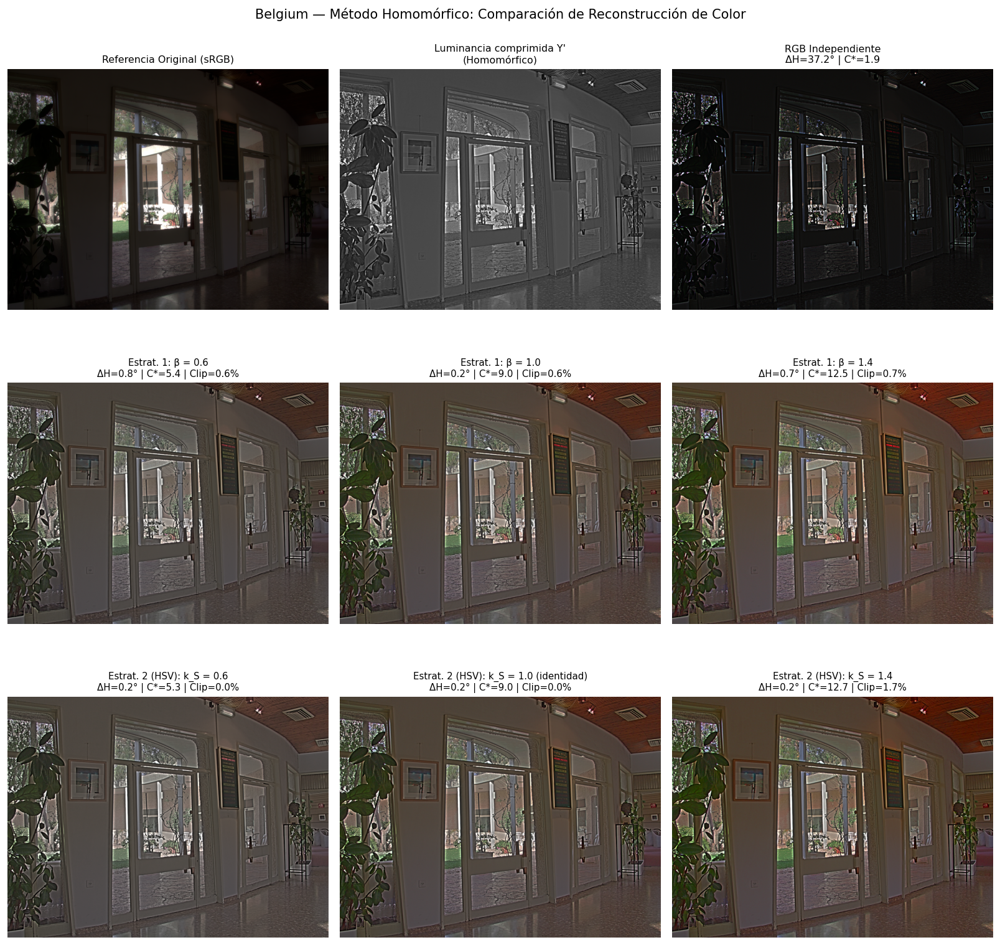

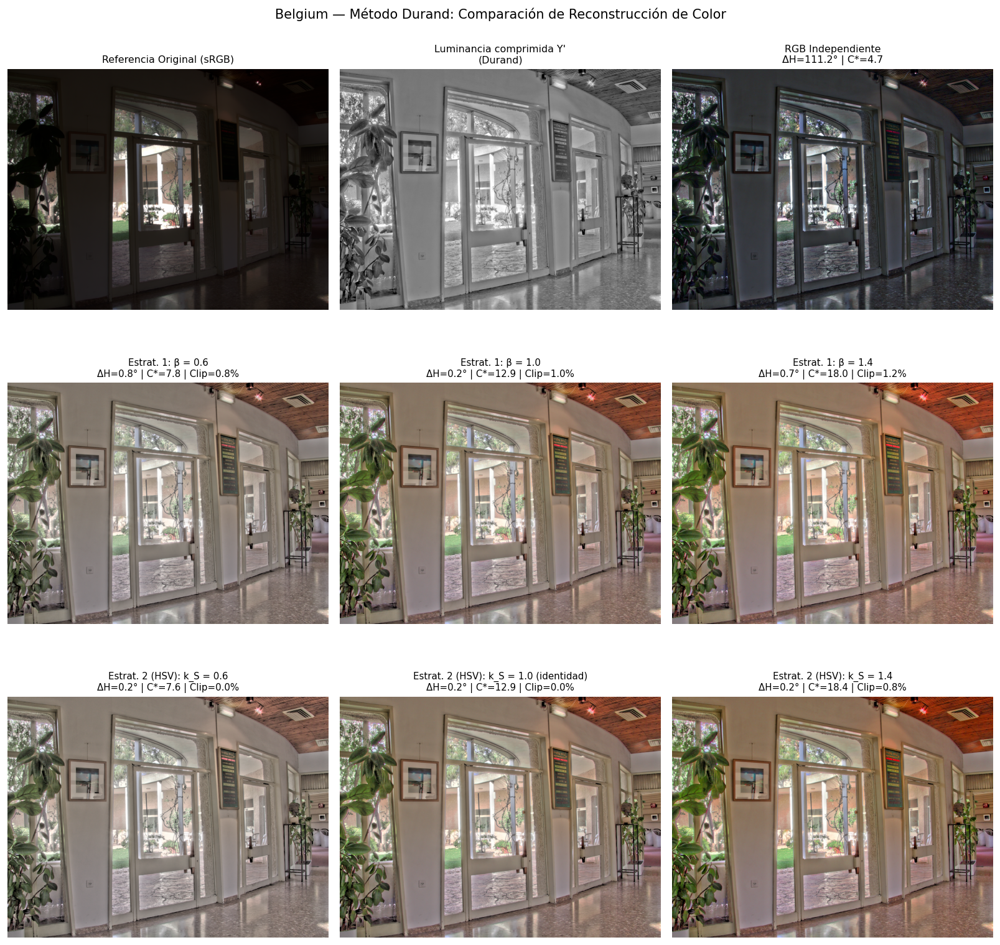

In [15]:
for img_name in ["memorial", "belgium"]:
    rgb_ref = results[img_name]["rgb_ref"]
    for m_name in ["Homomórfico", "Durand"]:
        m_data = results[img_name]["methods"][m_name]
        Y_comp = m_data["Y_comp"]
        rgb_indep, mt_indep = m_data["rgb_indep"]

        fig, axes = plt.subplots(3, 3, figsize=(13.5, 13.5))

        # Fila 0: Original, Y', RGB independiente
        axes[0, 0].imshow(rgb_ref)
        axes[0, 0].set_title("Referencia Original (sRGB)", fontsize=9.5)
        axes[0, 0].axis("off")

        axes[0, 1].imshow(linear_to_srgb(Y_comp), cmap="gray", vmin=0, vmax=1)
        axes[0, 1].set_title(f"Luminancia comprimida Y'\n({m_name})", fontsize=9.5)
        axes[0, 1].axis("off")

        axes[0, 2].imshow(rgb_indep)
        axes[0, 2].set_title(f"RGB Independiente\nΔH={mt_indep['Delta_H_deg']:.1f}° | C*={mt_indep['C_star_mean']:.1f}", fontsize=9.5)
        axes[0, 2].axis("off")

        # Fila 1: Estrategia 1 (beta)
        for idx, b in enumerate(betas):
            rec_b, mt_b = m_data["beta"][b]
            axes[1, idx].imshow(rec_b)
            axes[1, idx].set_title(
                f"Estrat. 1: β = {b}\nΔH={mt_b['Delta_H_deg']:.1f}° | C*={mt_b['C_star_mean']:.1f} | Clip={mt_b['Clip_pct']:.1f}%",
                fontsize=9
            )
            axes[1, idx].axis("off")

        # Fila 2: Estrategia 2 (HSV S)
        for idx, ks in enumerate(sat_gains):
            rec_k, mt_k = m_data["hsv"][ks]
            id_str = " (identidad)" if ks == 1.0 else ""
            axes[2, idx].imshow(rec_k)
            axes[2, idx].set_title(
                f"Estrat. 2 (HSV): k_S = {ks}{id_str}\nΔH={mt_k['Delta_H_deg']:.1f}° | C*={mt_k['C_star_mean']:.1f} | Clip={mt_k['Clip_pct']:.1f}%",
                fontsize=9
            )
            axes[2, idx].axis("off")

        plt.suptitle(f"{img_name.capitalize()} — Método {m_name}: Comparación de Reconstrucción de Color", fontsize=12.5)
        plt.tight_layout()
        fname = OUTPUT_DIR / f"01_{img_name}_{m_name.lower().replace('ó', 'o')}_grilla.png"
        plt.savefig(fname, bbox_inches="tight")
        plt.show()

## 5. Recortes Ampliados: Colores Intensos vs. Transición Fuerte de Iluminación

1. **Recorte A — Colores intensos (`memorial.tif`):** Zona central-superior de los vitrales saturados rodeados de piedra oscura. Permite evaluar cómo $\beta > 1$ frente a $k_S > 1$ afecta el *clipping* de canales y la naturalidad del color.
2. **Recorte B — Transición fuerte de iluminación (`belgium.tif`):** Frontera entre el interior en sombra profunda y la abertura exterior muy iluminada. Permite contrastar los halos alrededor de bordes de alto contraste entre **Homomórfico** y **Durand**.

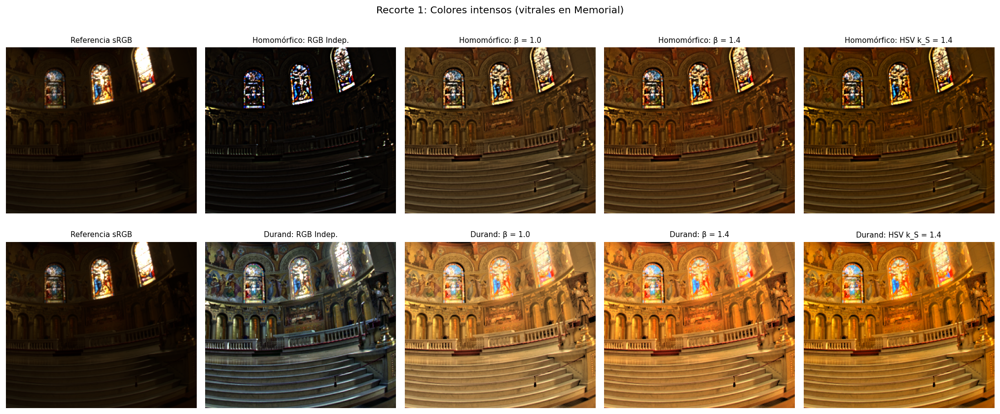

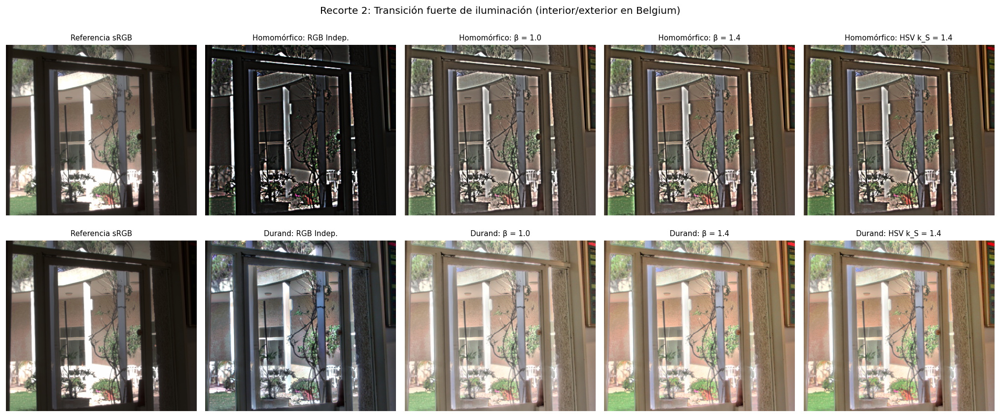

In [16]:
# Definir recortes representativos
Hm, Wm = results["memorial"]["rgb_ref"].shape[:2]
crop_mem = (slice(int(0.58 * Hm), int(0.90 * Hm)), slice(int(0.40 * Wm), int(0.95 * Wm)))

Hb, Wb = results["belgium"]["rgb_ref"].shape[:2]
crop_bel = (slice(int(0.25 * Hb), int(0.68 * Hb)), slice(int(0.32 * Wb), int(0.68 * Wb)))

crop_specs = [
    ("memorial", crop_mem, "Recorte 1: Colores intensos (vitrales en Memorial)"),
    ("belgium", crop_bel, "Recorte 2: Transición fuerte de iluminación (interior/exterior en Belgium)"),
]

for img_name, (sl_r, sl_c), title_txt in crop_specs:
    rgb_ref = results[img_name]["rgb_ref"][sl_r, sl_c]

    fig, axes = plt.subplots(2, 5, figsize=(17, 7.5))
    for row_idx, m_name in enumerate(["Homomórfico", "Durand"]):
        m_data = results[img_name]["methods"][m_name]
        panels = [
            ("Referencia sRGB", rgb_ref),
            (f"{m_name}: RGB Indep.", m_data["rgb_indep"][0][sl_r, sl_c]),
            (f"{m_name}: β = 1.0", m_data["beta"][1.0][0][sl_r, sl_c]),
            (f"{m_name}: β = 1.4", m_data["beta"][1.4][0][sl_r, sl_c]),
            (f"{m_name}: HSV k_S = 1.4", m_data["hsv"][1.4][0][sl_r, sl_c]),
        ]
        for col_idx, (p_title, p_img) in enumerate(panels):
            axes[row_idx, col_idx].imshow(p_img)
            axes[row_idx, col_idx].set_title(p_title, fontsize=9)
            axes[row_idx, col_idx].axis("off")

    plt.suptitle(title_txt, fontsize=12)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"02_recorte_{img_name}.png", bbox_inches="tight")
    plt.show()

### Lectura de las comparaciones visuales

El recorte de Memorial ahora incluye los vitrales coloridos y el de Belgium contiene la transicion entre el exterior iluminado y el interior en sombra. Las grillas mantienen fijos los parametros de cada metodo HDR y permiten contrastar las reconstrucciones; en las variantes con mayor saturacion se aprecia el aumento de color y, en Memorial, una apariencia mas intensa que la referencia.